# 07 — Depth-resolved stiffness and the T47DR shape signal

Notebook 06 left two open points:

1. **The T47DR shape signal.** In T47DR the amplitude-normalised curve shape separates nucleus and cytoplasm (AUC ≈ 0.76) better than the scalar features (≈ 0.63). Is it a real property of the curves or an artifact of the contact-point estimate?
2. **A stiffness estimate without the Hertz fit.** The force at one fixed indentation confirmed the nucleus-softer result. How does the nucleus–cytoplasm difference depend on **indentation depth**, and does it hold also at **fixed force**?

**What this notebook does**

- builds depth-resolved profiles for every curve: force $F(\delta_0)$ at fixed indentations, indentation $\delta(F_0)$ at fixed forces, and the amplitude-normalised shape recomputed for five **shifted contact points**; they are saved in `results/` (tracked), so the analysis runs without the raw data;
- measures the nucleus–cytoplasm difference $\Delta$ as a function of depth, with bootstrap intervals, for $\log F(\delta_0)$, for the local effective stiffness $\log[F/\delta_0^{3/2}]$ and for $\log\delta(F_0)$;
- tests the T47DR shape signal: shape-only AUC versus contact-point shift, permutation test, comparison with trivial covariates ($\delta_{max}$, $F_{max}$), where along the curve the shapes differ.

**What it does NOT do**

- it does not exclude curves, and it does not change the fit parameters of notebook 02;
- it does not turn the effective stiffness into a Young modulus (tip geometry and Poisson ratio are unknown);
- all caveats of notebooks 03–06 hold (pseudo-replication, line ≡ session, pre-selected sample).

Region labels follow the data folders: `cito` = cytoplasm, `nucleo` = nucleus.

In [1]:
import warnings, json; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
from scipy.ndimage import gaussian_filter1d
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import roc_auc_score
import afm_tools as T

T.set_plot_style()
SEED = 20261016; RNG = np.random.default_rng(SEED)
fit = T.load_fit_table(); fit = fit[fit.fit_status == "ok"].reset_index(drop=True)
summary = {}; lines = ["MCF7R", "T47DR"]

## 1. Depth-resolved profiles

For each curve the baseline-corrected force beyond the fitted contact point $z_c$ gives $F(\delta)$ with $\delta=z_c-z$ (smoothed over ~5 samples). From it:

- $F(\delta_0)$ at $\delta_0=50,100,\dots,600$ nm (NaN when the curve does not reach $\delta_0$);
- $\delta(F_0)$ at $F_0=0.1,0.2,0.3$ nN (the indentation needed to reach a given force; NaN if $F_{max}<F_0$);
- the shape $F/F_{max}$ on 30 points of $\delta/\delta_{max}\in[0.05,1]$ for the contact point shifted by $-50,-20,0,+20,+50$ nm, to test the sensitivity to the contact-point estimate.

In [2]:
D0 = np.arange(0.05, 0.601, 0.05); F0 = np.array([0.1, 0.2, 0.3]); SHIFTS = [-0.05, -0.02, 0.0, 0.02, 0.05]; NU = 30; U = np.linspace(0.05, 1, NU)
PROF_PATH = T.RESULTS_DIR / "force_indentation_profiles.csv"

def profile(z, f):
    r = T.fit_curve(z, f, return_arrays=True)
    if r["fit_status"] != "ok": return None
    a = r["_arrays"]; zc = r["contact_z_fit_um"]; out = {}
    F_s = gaussian_filter1d(a["fcorr"], sigma=5)
    for s in SHIFTS:
        m = a["z"] < zc + s; d = zc + s - a["z"][m]; F = F_s[m]; o = np.argsort(d); d, F = d[o], F[o]; dmax, fmax = d.max(), max(F.max(), 1e-9)
        if s == 0.0:
            for d0 in D0: out[f"F_{int(round(1000 * d0))}nm"] = float(np.interp(d0, d, F)) if dmax >= d0 else np.nan
            Fm = np.maximum.accumulate(F)
            for f0 in F0: out[f"d_at_{int(round(1000 * f0))}pN"] = float(np.interp(f0, Fm, d)) if fmax >= f0 else np.nan
            out["dmax_um"] = dmax; out["fmax_nN"] = fmax
        for i, v in enumerate(np.interp(U * dmax, d, F) / fmax): out[f"sh{int(round(1000 * s)):+d}_{i:02d}"] = v
    return out

if T.MANIFEST_PATH.exists():
    man = T.load_manifest(); rows = []
    for _, m in man.iterrows():
        z, f = T.read_curve(T.CODE_DIR / m["csv_path"]); p = profile(z, f)
        if p is not None: rows.append(dict(file_name=m["file_name"], group=m["group"], **p))
    prof = pd.DataFrame(rows); prof.to_csv(PROF_PATH, index=False); print("rebuilt", PROF_PATH.name, prof.shape)
else:
    prof = pd.read_csv(PROF_PATH); print("read", PROF_PATH.name, prof.shape)
df = fit.merge(prof, on=["file_name", "group"], suffixes=("", "_p")); print(len(df), "curves")

rebuilt force_indentation_profiles.csv (257, 169)
257 curves


## 2. Nucleus–cytoplasm difference versus indentation depth

For each depth $\delta_0$ we compute, per line, $\Delta(\delta_0)=\langle\log F\rangle_{nucleus}-\langle\log F\rangle_{cytoplasm}$ (95% bootstrap interval) and the same for the **local effective stiffness** $\log[F(\delta_0)/\delta_0^{3/2}]$, which for a pure Hertz curve equals $\log A$ at every depth. If the Hertz model holds, the effective stiffness is constant with depth and its $\Delta$ equals $\Delta\log A$; a trend with depth reveals a layered or non-Hertzian response (e.g. the nucleus seen through the cytoplasm).

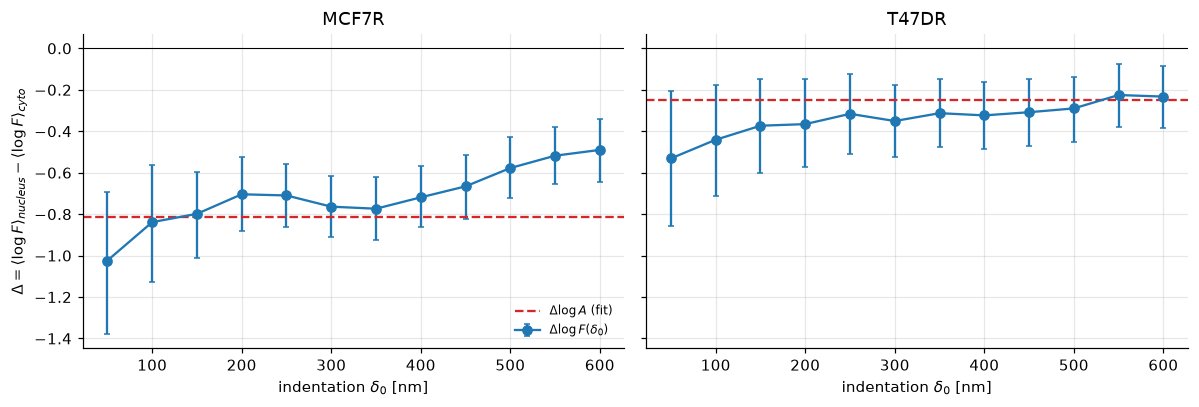

,line,depth_nm,n_cito,n_nucleo,dlogF,lo,hi,p
0,MCF7R,50,44,35,-1.024,-1.378,-0.692,0.000
1,MCF7R,100,52,49,-0.839,-1.126,-0.561,0.000
2,MCF7R,150,54,60,-0.798,-1.011,-0.596,0.000
3,MCF7R,200,55,60,-0.704,-0.883,-0.523,0.000
4,MCF7R,250,55,60,-0.710,-0.860,-0.556,0.000
5,MCF7R,300,55,60,-0.764,-0.912,-0.615,0.000
6,MCF7R,350,54,60,-0.774,-0.925,-0.619,0.000
7,MCF7R,400,49,60,-0.719,-0.862,-0.570,0.000
8,MCF7R,450,44,60,-0.666,-0.823,-0.516,0.000
9,MCF7R,500,38,60,-0.577,-0.720,-0.430,0.000


In [3]:
def delta_ci(xn, xc, nb=4000, seed=0):
    rg = np.random.default_rng(seed); bn = rg.choice(xn, (nb, len(xn))).mean(1); bc = rg.choice(xc, (nb, len(xc))).mean(1); b = bn - bc
    return xn.mean() - xc.mean(), np.quantile(b, .025), np.quantile(b, .975), stats.ttest_ind(xn, xc, equal_var=False).pvalue

rows = []
for l in lines:
    d = df[df.cell_line == l]
    for d0 in D0:
        col = f"F_{int(round(1000 * d0))}nm"; v = d.dropna(subset=[col]); v = v[v[col] > 1e-3]
        xn, xc = np.log(v[v.region == "nucleo"][col].to_numpy()), np.log(v[v.region == "cito"][col].to_numpy())
        if min(len(xn), len(xc)) < 15: continue
        a = delta_ci(xn, xc); b = delta_ci(xn - 1.5 * np.log(d0), xc - 1.5 * np.log(d0))
        rows.append(dict(line=l, depth_nm=int(round(1000 * d0)), n_cito=len(xc), n_nucleo=len(xn), dlogF=a[0], lo=a[1], hi=a[2], p=a[3]))
depth = pd.DataFrame(rows); summary["delta_vs_depth"] = depth.round(4).to_dict("records")
dA = {l: df[(df.cell_line == l) & (df.region == "nucleo")].logA.mean() - df[(df.cell_line == l) & (df.region == "cito")].logA.mean() for l in lines}
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for a_, l in zip(ax, lines):
    t = depth[depth.line == l]; a_.errorbar(t.depth_nm, t.dlogF, [t.dlogF - t.lo, t.hi - t.dlogF], marker="o", capsize=2, label=r"$\Delta\log F(\delta_0)$")
    a_.axhline(0, c="k", lw=.7); a_.axhline(dA[l], c="C3", ls="--", label=r"$\Delta\log A$ (fit)"); a_.set_title(l); a_.set_xlabel(r"indentation $\delta_0$ [nm]")
ax[0].set_ylabel(r"$\Delta=\langle\log F\rangle_{nucleus}-\langle\log F\rangle_{cyto}$"); ax[0].legend(fontsize=8); plt.tight_layout(); plt.show()
depth.round(3)

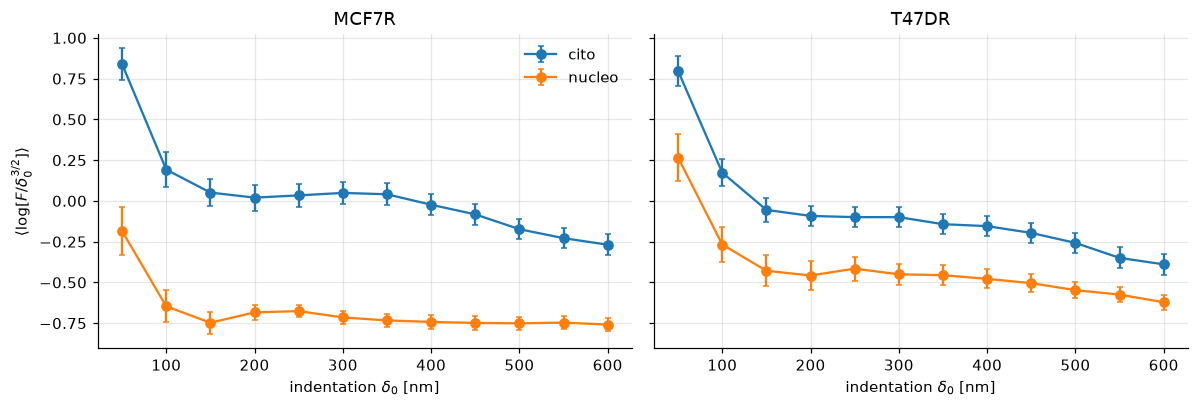

slope of <log A_eff> per 100 nm of depth: {'MCF7R cito': -0.128, 'MCF7R nucleo': -0.054, 'T47DR cito': -0.139, 'T47DR nucleo': -0.096}


In [4]:
# local effective stiffness log[F/delta0^1.5] versus depth, per group (constant if the Hertz law holds)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True); eff_rows = []
for a_, l in zip(ax, lines):
    for r_, c in [("cito", "C0"), ("nucleo", "C1")]:
        d = df[(df.cell_line == l) & (df.region == r_)]; ys, xs, es = [], [], []
        for d0 in D0:
            col = f"F_{int(round(1000 * d0))}nm"; v = d[col].dropna(); v = v[v > 1e-3]
            if len(v) < 15: continue
            y = np.log(v / d0 ** 1.5); xs.append(1000 * d0); ys.append(y.mean()); es.append(y.std() / np.sqrt(len(y))); eff_rows.append(dict(line=l, region=r_, depth_nm=int(1000 * d0), n=len(y), mean_log_Aeff=y.mean(), sem=y.std() / np.sqrt(len(y))))
        a_.errorbar(xs, ys, es, marker="o", color=c, capsize=2, label=r_)
    a_.set_title(l); a_.set_xlabel(r"indentation $\delta_0$ [nm]")
ax[0].set_ylabel(r"$\langle\log[F/\delta_0^{3/2}]\rangle$"); ax[0].legend(); plt.tight_layout(); plt.show()
eff = pd.DataFrame(eff_rows); summary["effective_stiffness_vs_depth"] = eff.round(4).to_dict("records")
slope = {f"{l} {r_}": float(np.polyfit(g.depth_nm, g.mean_log_Aeff, 1)[0] * 100) for (l, r_), g in eff.groupby(["line", "region"])}
summary["effective_stiffness_slope_per_100nm"] = slope; print("slope of <log A_eff> per 100 nm of depth:", {k: round(v, 3) for k, v in slope.items()})

## 3. Fixed force instead of fixed depth

The complementary model-free observable: the indentation $\delta(F_0)$ needed to reach a given force. A softer sample needs a *larger* $\delta(F_0)$, so the expected sign of $\Delta\log\delta(F_0)$ is **positive** for a softer nucleus.

In [5]:
rows = []
for l in lines:
    d = df[df.cell_line == l]
    for f0 in F0:
        col = f"d_at_{int(round(1000 * f0))}pN"; v = d.dropna(subset=[col]); v = v[v[col] > 1e-3]
        xn, xc = np.log(v[v.region == "nucleo"][col].to_numpy()), np.log(v[v.region == "cito"][col].to_numpy()); a = delta_ci(xn, xc)
        rows.append(dict(line=l, F0_nN=f0, n_cito=len(xc), n_nucleo=len(xn), dlog_delta=a[0], lo95=a[1], hi95=a[2], p_welch=a[3]))
fixed_force = pd.DataFrame(rows).set_index(["line", "F0_nN"]); summary["delta_fixed_force"] = {f"{k[0]}|{k[1]}": v for k, v in fixed_force.round(5).to_dict("index").items()}; fixed_force.round(4)

n_cito  n_nucleo  dlog_delta    lo95    hi95  p_welch
line  F0_nN                                                       
MCF7R 0.1        55        60      0.5531  0.4518  0.6566   0.0000
      0.2        55        60      0.5383  0.4384  0.6394   0.0000
      0.3        55        59      0.5431  0.4437  0.6406   0.0000
T47DR 0.1        59        83      0.1897  0.0627  0.3140   0.0039
      0.2        59        83      0.1458  0.0185  0.2675   0.0246
      0.3        59        83      0.1637  0.0357  0.2866   0.0119

## 4. The T47DR shape signal

**(a) Where do the shapes differ?** Mean amplitude-normalised shape of nucleus and cytoplasm in each line, with 95% bootstrap bands of their difference, for the nominal contact point.

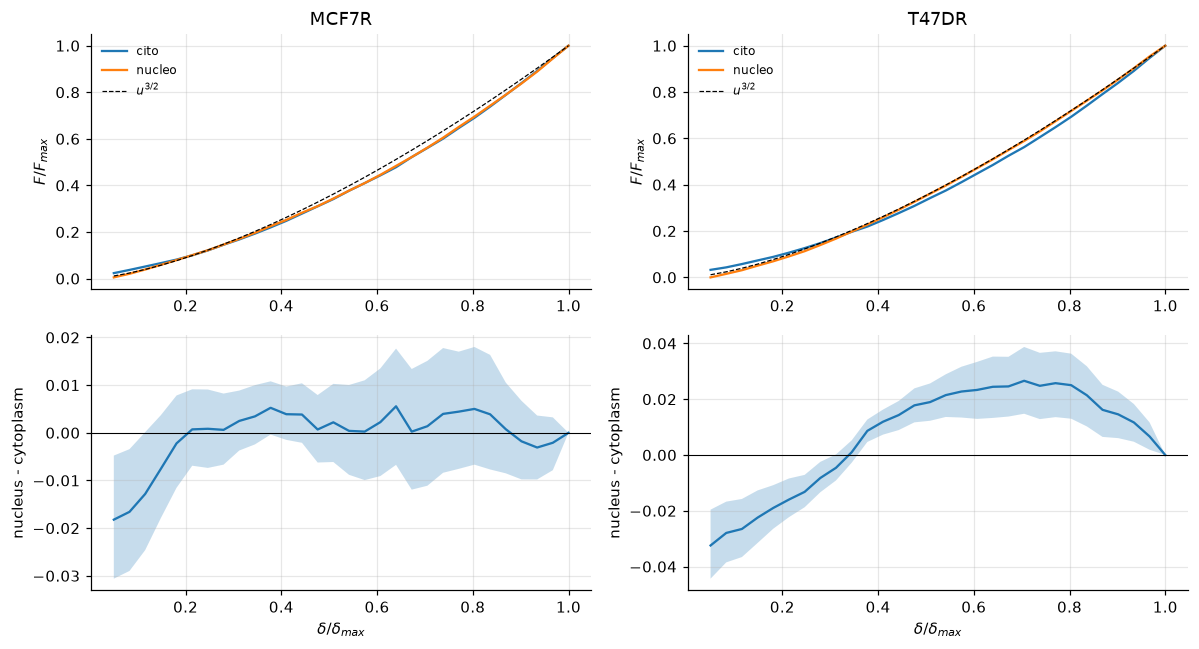

{'MCF7R': {'u_at_max': 0.05, 'max_abs': 0.018082420649824207, 'fraction_u_significant': 0.06666666666666667}, 'T47DR': {'u_at_max': 0.05, 'max_abs': 0.0323791135169004, 'fraction_u_significant': 0.9}}


In [6]:
SH = {s: [f"sh{int(round(1000 * s)):+d}_{i:02d}" for i in range(NU)] for s in SHIFTS}
fig, ax = plt.subplots(2, 2, figsize=(11, 6))
for j, l in enumerate(lines):
    d = df[df.cell_line == l]; sn, sc = d[d.region == "nucleo"][SH[0.0]].to_numpy(), d[d.region == "cito"][SH[0.0]].to_numpy()
    for s_, lab_ in [(sc, "cito"), (sn, "nucleo")]: ax[0, j].plot(U, s_.mean(0), label=lab_)
    ax[0, j].plot(U, U ** 1.5, "k--", lw=.8, label=r"$u^{3/2}$"); ax[0, j].set_title(l); ax[0, j].legend(fontsize=8); ax[0, j].set_ylabel(r"$F/F_{max}$")
    bs = np.array([RNG.choice(len(sn), len(sn)) for _ in range(2000)]); bc = np.array([RNG.choice(len(sc), len(sc)) for _ in range(2000)])
    diff = np.array([sn[i].mean(0) - sc[k].mean(0) for i, k in zip(bs, bc)]); lo, hi = np.quantile(diff, [.025, .975], axis=0)
    ax[1, j].plot(U, sn.mean(0) - sc.mean(0)); ax[1, j].fill_between(U, lo, hi, alpha=.25); ax[1, j].axhline(0, c="k", lw=.7)
    ax[1, j].set_xlabel(r"$\delta/\delta_{max}$"); ax[1, j].set_ylabel("nucleus - cytoplasm")
    summary.setdefault("shape_difference_peak", {})[l] = dict(u_at_max=float(U[np.argmax(np.abs(diff.mean(0)))]), max_abs=float(np.abs(diff.mean(0)).max()), fraction_u_significant=float(((lo > 0) | (hi < 0)).mean()))
plt.tight_layout(); plt.show(); print(summary["shape_difference_peak"])

**(b) Sensitivity to the contact point.** Shape-only AUC (PCA(5) + logistic, 5-fold × 5) for the contact point shifted by $\pm20$ and $\pm50$ nm. A genuine property of the curve should survive small shifts; an artifact of the contact estimate would change with them. A permutation test (200 shuffles of the labels) gives the chance level, and trivial covariates ($\delta_{max}$, $F_{max}$) are used as reference.

In [7]:
def cv_auc(model, X, y, n_rep=5):
    return np.mean([roc_auc_score(y, cross_val_predict(model, X, y, cv=StratifiedKFold(5, shuffle=True, random_state=SEED + r), method="predict_proba")[:, 1]) for r in range(n_rep)])
shape_model = lambda: make_pipeline(StandardScaler(), PCA(5), LogisticRegression(max_iter=2000))
simple = lambda: make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
rows = []
for l in lines:
    d = df[df.cell_line == l].reset_index(drop=True); y = (d.region == "nucleo").astype(int).to_numpy()
    row = dict(line=l)
    for s in SHIFTS: row[f"shape_{int(round(1000 * s)):+d}nm"] = cv_auc(shape_model(), d[SH[s]].to_numpy(), y)
    row["dmax+Fmax_only"] = cv_auc(simple(), np.c_[np.log(d.dmax_um_p if "dmax_um_p" in d else d.dmax_um), np.log(d.fmax_nN_p if "fmax_nN_p" in d else d.fmax_nN)], y)
    row["exponent_only"] = cv_auc(simple(), d[["exponent_hat"]].to_numpy(), y)
    row["logA_only"] = cv_auc(simple(), d[["logA"]].to_numpy(), y)
    null = [cv_auc(shape_model(), d[SH[0.0]].to_numpy(), RNG.permutation(y), 1) for _ in range(150)]
    row["perm_null_mean"] = np.mean(null); row["p_perm_shape"] = (np.sum(np.array(null) >= row["shape_+0nm"]) + 1) / 151
    rows.append(row)
sens = pd.DataFrame(rows).set_index("line"); summary["shape_auc_vs_contact_shift"] = sens.round(4).to_dict("index"); sens.round(3)

,shape_-50nm,shape_-20nm,shape_+0nm,shape_+20nm,shape_+50nm,dmax+Fmax_only,exponent_only,logA_only,perm_null_mean,p_perm_shape
line,,,,,,,,,,
MCF7R,0.845,0.665,0.610,0.793,0.883,0.941,0.468,0.907,0.492,0.046
T47DR,0.752,0.767,0.764,0.768,0.783,0.637,0.764,0.634,0.496,0.007


**(c) Is the signal in the shape or in the exponent?** The first PCA components of the T47DR shapes against the free exponent, and the shape-only AUC after regressing out the free exponent (residual shape), to see whether the information is just the local power-law exponent.

Spearman of PC1-3 with the free exponent: [ 0.66 -0.49  0.43]  | AUC shape: 0.764  AUC residual shape (exponent, dmax, Fmax removed): 0.581


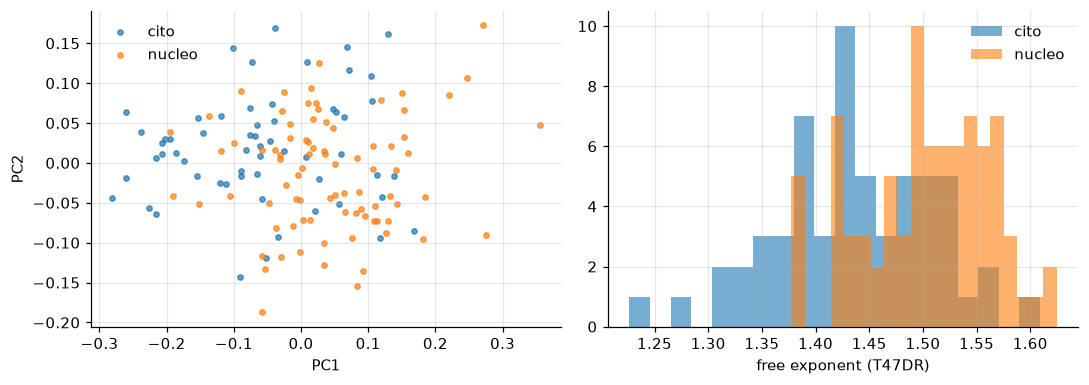

In [8]:
d = df[df.cell_line == "T47DR"].reset_index(drop=True); y = (d.region == "nucleo").astype(int).to_numpy(); X0 = d[SH[0.0]].to_numpy()
pca = PCA(5).fit(X0); Zs = pca.transform(X0); rho = [stats.spearmanr(Zs[:, k], d.exponent_hat)[0] for k in range(3)]
# residual shape after removing the linear dependence on exponent, log dmax and log fmax (fit on all curves: it only removes smooth covariate trends)
cov = np.c_[d.exponent_hat, np.log(d.dmax_um), np.log(d.fmax_nN)]; Xr = X0 - np.c_[np.ones(len(d)), cov] @ np.linalg.lstsq(np.c_[np.ones(len(d)), cov], X0, rcond=None)[0]
auc_res = cv_auc(shape_model(), Xr, y)
print("Spearman of PC1-3 with the free exponent:", np.round(rho, 2), " | AUC shape:", round(cv_auc(shape_model(), X0, y), 3), " AUC residual shape (exponent, dmax, Fmax removed):", round(auc_res, 3))
summary["T47DR_shape"] = dict(spearman_pc_vs_exponent=[float(r) for r in rho], auc_shape=float(cv_auc(shape_model(), X0, y)), auc_residual_shape=float(auc_res))
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
for r_, c in [("cito", "C0"), ("nucleo", "C1")]:
    m = (d.region == r_).to_numpy(); ax[0].scatter(Zs[m, 0], Zs[m, 1], s=12, c=c, label=r_, alpha=.7); ax[1].hist(d[m].exponent_hat, bins=20, alpha=.6, color=c, label=r_)
ax[0].set_xlabel("PC1"); ax[0].set_ylabel("PC2"); ax[0].legend(); ax[1].set_xlabel("free exponent (T47DR)"); ax[1].legend(); plt.tight_layout(); plt.show()

**(d) The free exponent by region.** The local power-law exponent from the free fit, compared between regions (Mann–Whitney), with the AUC of the exponent alone.

In [9]:
rows = []
for l in lines:
    d = df[df.cell_line == l]; a = d[d.region == "nucleo"].exponent_hat.to_numpy(); b = d[d.region == "cito"].exponent_hat.to_numpy()
    rows.append(dict(line=l, median_nucleo=np.median(a), median_cito=np.median(b), diff=np.median(a) - np.median(b), p_mw=stats.mannwhitneyu(a, b).pvalue,
                     auc_exponent=roc_auc_score(np.r_[np.ones(len(a)), np.zeros(len(b))], np.r_[a, b])))
expo = pd.DataFrame(rows).set_index("line"); summary["exponent_by_region"] = expo.round(5).to_dict("index")
json.dump(summary, open(T.RESULTS_DIR / "07_summary.json", "w"), indent=1, default=float); expo.round(4)

,median_nucleo,median_cito,diff,p_mw,auc_exponent
line,,,,,
MCF7R,1.4512,1.4409,0.0103,0.7222,0.5194
T47DR,1.5024,1.4334,0.0690,0.0000,0.7688


## Interpretation and limits

- **Depth.** The nucleus is softer than the cytoplasm at **every** indentation in both lines, with intervals excluding zero: $\Delta\log F$ goes from $-1.0$ (50 nm) to $-0.5$ (600 nm) in MCF7R and from $-0.5$ to $-0.2$ in T47DR. The difference shrinks with depth, but beyond ≈ 400 nm fewer curves reach the depth (the deepest ones are the softest), so the subsets change and the trend at large depth is partly a selection effect; the 150–400 nm range, where almost all curves contribute, is the reliable one ($\Delta\approx-0.7$ to $-0.8$ for MCF7R, $\approx-0.3$ to $-0.4$ for T47DR).
- **Effective stiffness.** $\langle\log[F/\delta_0^{3/2}]\rangle$ decreases with depth by roughly 0.05–0.14 per 100 nm in all groups: the response is not exactly a single 3/2 power law (sub-Hertzian, consistent with the free exponent slightly below 1.5), with the same qualitative behaviour in both regions, so the relative comparison is not affected.
- **Fixed force.** The nucleus needs a larger indentation to reach the same force: $\Delta\log\delta(F_0)\approx+0.54$ in MCF7R (about 1.7 times deeper) and $+0.15$ to $+0.19$ in T47DR (95% intervals excluding zero, $p=0.004$–$0.03$). A second model-free confirmation of the softer nucleus.
- **T47DR shape signal.** The shape-only AUC ($\approx0.76$) is stable for contact-point shifts of $\pm50$ nm ($0.75$–$0.78$) and well above the permutation null ($p=0.007$): it is not an artifact of the contact estimate. It is, however, **entirely the local exponent**: the exponent alone gives AUC $0.764$, and after regressing out the exponent, $\delta_{max}$ and $F_{max}$ the residual shape drops to $0.58$. In T47DR the nuclear curves have a higher free exponent (median 1.50 against 1.43, Mann–Whitney $p\approx5\cdot10^{-8}$), whereas in MCF7R the exponent does not differ (1.45 against 1.44). This is a statistically stronger regional difference than that of $A$ ($p\approx0.01$), but small in absolute size (0.07), and it can reflect a genuinely different contact law (nuclear geometry, thickness) or the contact estimate.
- **Shift test in MCF7R.** For MCF7R the shape-only AUC changes strongly with the contact shift (0.61 at 0 nm, 0.85–0.88 at ±50 nm): shifting the contact point makes the normalised shape depend on the amplitude ($\delta_{max}$ alone gives 0.94), so these values must not be read as a shape signal.
- All caveats hold: pseudo-replication (cross-validation inside the same cells is optimistic), line ≡ session, pre-selected sample.

## Output produced

```text
results/force_indentation_profiles.csv   F(δ0), δ(F0) and shapes for shifted contact points, per curve (tracked)
results/07_summary.json                  Δ vs depth, effective stiffness vs depth, fixed force, T47DR shape tests
```

Next steps outside this pipeline: repeat the analysis with the cell identifier, and with the laboratory's defective curves for validating the detectors.